# Gold-news sentiment and commodity portfolio allocation
**Part 5 · Ons Jdey & Senghak Rou · ML for Portfolio Management and Trading**

## 1. Research objective and hypotheses
Does monthly gold-news sentiment add useful information to commodity and macroeconomic regimes? This experiment extends Notebooks 01–04, retaining their features, conditional moment estimates and constrained Markowitz procedure.

| Strategy | Allocation rule | Regime features |
|:--|:--|:--|
| A | Equal weight | — |
| B | Classical Markowitz | — |
| C | KMeans-conditioned Markowitz | Commodity + FRED (21) |
| D | KMeans-conditioned Markowitz | Commodity + FRED + sentiment (22) |
| E | GMM-conditioned Markowitz | Commodity + FRED (21) |
| F | GMM-conditioned Markowitz | Commodity + FRED + sentiment (22) |

The primary effects are $\Delta SR_{\mathrm{KM}}=SR_D-SR_C$ and $\Delta SR_{\mathrm{GMM}}=SR_F-SR_E$. The improvement hypotheses are that these differences are positive. We report both effects and paired uncertainty, without selecting a preferred model from evaluation Sharpe ratios.

**Research status.** July 2016–December 2018 has been examined during previous project development. It is a chronological evaluation sample, **not a completely untouched research holdout**. Results concern monthly World Bank benchmark-price changes, not investable futures total returns. This is not a fully point-in-time trading backtest: the dollar-index methodology itself was introduced in 2019 and backfilled into the study period (Section 7).

**Observed result:** sentiment lowers sample Sharpe for both algorithms (KMeans: −0.168; GMM: −0.028), with both paired 95% intervals including zero. Sentiment changes KMeans hard assignments and target allocations more than their GMM counterparts; neither comparison establishes improved performance. Detailed estimates and uncertainty follow in Section 6.

**Reproduction.** Run all cells from the repository root in Python 3. The notebook reads the existing local data and the pinned public news dataset; the first news load requires internet access, subsequent runs may use Hugging Face's standard cache. Install the repository requirements plus `datasets`, `nbclient` and `ipykernel` if needed. All computations and outputs stay in this notebook; Notebooks 01–04 are not executed or modified.

The presentation follows the professor's `92_Project_template`: question, data, chronological learning, baseline results, robustness and limitations. The relevant course notebooks are `10_Mean_variance_estimators`, `11_Backtesting`, `19_Hyperparameter_optimisation`, `30_Transaction_cost`, `41_Timing_backtest_with_learning` and `46_Text_processing` in [the course repository](https://github.com/schampon/skfin/tree/master/nbs). The implementation authority is the executable code in Notebooks 01–04; the course's alternative optimization and turnover conventions are not substituted here.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.optimize import minimize, linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from datasets import load_dataset, disable_progress_bars
from IPython.display import display, Markdown

disable_progress_bars()
BASE = Path.cwd()
assert (BASE / "data/raw").exists(), "Run from the project root."
SEED = 42
START, END = pd.Timestamp("2006-04-01"), pd.Timestamp("2018-12-01")
TRAIN_END, MODEL_END = pd.Timestamp("2012-12-01"), pd.Timestamp("2015-12-01")
EVAL_START = pd.Timestamp("2016-07-01")
LOOKBACK, LAG, PRIOR, MIN_EFFECTIVE = 120, 2, 24, 12
GAMMA, CAP, MEAN_SHRINK, COV_SHRINK, FEE_BPS = 5.0, .60, .50, .20, 10
DATASET_ID = "SaguaroCapital/sentiment-analysis-in-commodity-market-gold"
DATASET_REVISION = "4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5"
NAMES = list("ABCDEF")
DESCRIPTIONS = dict(zip(NAMES, ["Equal weight", "Markowitz", "KMeans market",
                              "KMeans + sentiment", "GMM market", "GMM + sentiment"]))
plt.rcParams.update({"font.size": 10, "figure.figsize": (10, 4),
                     "axes.grid": True, "grid.alpha": .2,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"A": "#666666", "B": "#111111", "C": "#235789", "D": "#235789",
          "E": "#A76B00", "F": "#A76B00"}
STYLES = {"A": ":", "B": "-.", "C": "--", "D": "-", "E": "--", "F": "-"}
print("Python", sys.version.split()[0])
print({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn",
                              "matplotlib", "datasets", "openpyxl"]})

Python 3.12.6
{'numpy': '2.4.4', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.0', 'matplotlib': '3.10.9', 'datasets': '4.8.4', 'openpyxl': '3.1.5'}


## 2. Data sources and feature construction
### 2.1 Commodity prices and macroeconomic indicators
Use the preserved [World Bank Pink Sheet](https://www.worldbank.org/en/research/commodity-markets) snapshot and the four local daily FRED series: [VIXCLS](https://fred.stlouisfed.org/series/VIXCLS), [DTWEXBGS](https://fred.stlouisfed.org/series/DTWEXBGS), [DGS10](https://fred.stlouisfed.org/series/DGS10) and [DGS2](https://fred.stlouisfed.org/series/DGS2). Source manifests record retrieval on 7 November 2026; hashes below verify those raw snapshots. We also reconcile the processed commodity prices against the original workbook.

Let $P_{i,t}$ denote the monthly average price, $r_{i,t}=P_{i,t}/P_{i,t-1}-1$ its simple price change and $\ell_{i,t}=\log P_{i,t}-\log P_{i,t-1}$. The 15 commodity features are $\ell_{i,t}$, $\sum_{j=0}^{2}\ell_{i,t-j}$ and $\sqrt{12}\,\mathrm{sd}(\ell_{i,t-11:t})$ for each of five commodities.

Daily FRED observations are averaged within month, requiring at least ten valid days per series; holidays are neither zero-filled nor carried forward. The six macro features are log VIX, one- and three-month dollar log changes, the 10-year yield, its one-month change, and the 10y–2y slope. Yields and changes are in percentage points. All rolling features use trailing observations only. There is no block reweighting beyond per-feature standardization.

In [2]:
source_manifest = json.loads((BASE / "data/sources.json").read_text())
fred_manifest = json.loads((BASE / "data/fred_sources.json").read_text())
raw_paths = {"World Bank": (BASE / "data/raw/world_bank_monthly.xlsx", source_manifest["sha256"])}
raw_paths.update({item["series_id"]: (BASE / f"data/raw/fred/{item['series_id']}.csv", item["sha256"])
                  for item in fred_manifest})
for name, (path, expected_hash) in raw_paths.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash, name

prices = pd.read_csv(BASE / "data/processed/prices_2000_2025.csv", index_col="date", parse_dates=True)
prices = prices.loc["2000-01":END]
assert prices.index.equals(pd.date_range("2000-01-01", END, freq="MS"))
assert prices.index.is_unique and np.isfinite(prices).all().all() and prices.gt(0).all().all()
wb = pd.read_excel(BASE / "data/raw/world_bank_monthly.xlsx", sheet_name="Monthly Prices", header=4)
wb = wb.loc[wb.iloc[:, 0].astype(str).str.fullmatch(r"\d{4}M\d{2}")].copy()
wb.index = pd.to_datetime(wb.iloc[:, 0], format="%YM%m")
wb_map = {"Crude oil, Brent": "brent", "Natural gas, US": "natural_gas_us",
          "Gold": "gold", "Silver": "silver", "Copper": "copper"}
wb_prices = wb[list(wb_map)].rename(columns=wb_map).apply(pd.to_numeric)
np.testing.assert_allclose(prices, wb_prices.loc[prices.index, prices.columns], rtol=0, atol=1e-10)

monthly, counts = {}, {}
for sid in ["VIXCLS", "DTWEXBGS", "DGS10", "DGS2"]:
    daily = pd.read_csv(BASE / f"data/raw/fred/{sid}.csv", index_col=0, parse_dates=True)
    values = pd.to_numeric(daily[sid], errors="coerce").sort_index().loc[:"2018-12-31"]
    assert values.index.is_unique
    counts[sid] = values.resample("MS").count()
    monthly[sid] = values.resample("MS").mean().where(counts[sid] >= 10)
fred = pd.DataFrame(monthly).loc["2000-01":END]

def market_features(price_data, macro_data):
    log_returns = np.log(price_data).diff().dropna()
    commodity = pd.concat({"r1": log_returns, "mom3": log_returns.rolling(3).sum(),
                          "vol12": log_returns.rolling(12).std() * np.sqrt(12)}, axis=1).dropna()
    commodity.columns = ["__".join(c) for c in commodity.columns]
    macro = pd.DataFrame({
        "fred_log_vix": np.log(macro_data.VIXCLS),
        "fred_dollar_return_1m": np.log(macro_data.DTWEXBGS).diff(),
        "fred_dollar_momentum_3m": np.log(macro_data.DTWEXBGS).diff(3),
        "fred_yield10_level_pp": macro_data.DGS10,
        "fred_yield10_change_1m_pp": macro_data.DGS10.diff(),
        "fred_yield_slope_10y2y_pp": macro_data.DGS10 - macro_data.DGS2})
    return commodity.join(macro).replace([np.inf, -np.inf], np.nan).dropna()

X_market = market_features(prices, fred).loc[START:END]
ret = prices.pct_change(fill_method=None).dropna()
# Reconcile the reconstructed 21-feature block against Notebook 03's saved output.
existing_market = pd.read_csv(BASE / "data/processed/features_worldbank_fred.csv",
                              index_col=0, parse_dates=True)
np.testing.assert_allclose(X_market, existing_market.loc[X_market.index, X_market.columns], atol=1e-12)
print("Verified five raw-source hashes, workbook prices and Notebook 03 feature reconstruction.")

Verified five raw-source hashes, workbook prices and Notebook 03 feature reconstruction.


### 2.2 Gold-news sentiment
Reproduce Notebook 04 from the same [pinned SaguaroCapital dataset](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold/blob/4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5/README.md), which redistributes the [Sinha–Khandait corpus](https://arxiv.org/html/2009.04202). Combine its classification splits before making our chronological split. Parse dates strictly as day-month-year; remove invalid dates, out-of-window records and empty headlines/labels. For each normalized date–headline key, exclude all conflicting annotations; otherwise retain one record. These are the same rules as Notebook 04, including the separate `none` label.

The single added feature is
$$S_t=\frac{N_t^+-N_t^-}{N_t^{\mathrm{all}}},\qquad
N_t^{\mathrm{all}}=N_t^++N_t^-+N_t^{\mathrm{neutral}}+N_t^{\mathrm{none}}.$$
Counts and directional share are diagnostics only. Missing months fail validation rather than being imputed. **Sentiment remains indexed by its original observation month; no shift occurs in feature construction.** Retrospective labels describe gold-price statements and are not necessarily forward-looking forecasts.

The two observation vectors are $X_t^M\in\mathbb{R}^{21}$ and $X_t^{M+S}=(X_t^M,S_t)\in\mathbb{R}^{22}$, joined by their unshifted month-start dates.

In [3]:
LABELS = ["positive", "negative", "neutral", "none"]
BINARY_COLUMNS = ["Price Direction Up", "Price Direction Constant", "Price Direction Down",
                  "Asset Comparision", "Past Information", "Future Information"]
KEYS = ["date", "headline_key"]
splits = load_dataset(DATASET_ID, revision=DATASET_REVISION)
raw_news = pd.concat([part.to_pandas().assign(source_split=name) for name, part in splits.items()],
                     ignore_index=True)

def clean_news(raw):
    frame = raw.copy()
    frame["date"] = pd.to_datetime(frame["Dates"].astype("string").str.strip(),
                                    format="%d-%m-%Y", errors="coerce")
    frame["headline"] = frame["News"].astype("string").str.strip()
    frame["label"] = frame["Price Sentiment"].astype("string").str.strip().str.lower()
    frame["headline_key"] = frame["headline"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    remaining = pd.Series(True, index=frame.index)
    exclusions = {}
    for reason, mask in [
        ("invalid/missing date", frame.date.isna()),
        ("outside window", ~frame.date.between(START, END + pd.offsets.MonthEnd(0))),
        ("empty headline", frame.headline.isna() | frame.headline.eq("")),
        ("empty label", frame.label.isna() | frame.label.eq(""))]:
        removed = remaining & mask.fillna(False)
        exclusions[reason] = int(removed.sum())
        remaining &= ~removed
    candidate = frame.loc[remaining].copy()
    assert candidate.label.isin(LABELS).all()
    assert candidate[BINARY_COLUMNS].isin([0, 1]).all().all()
    conflicts = candidate.groupby(KEYS)[["label"] + BINARY_COLUMNS].nunique(dropna=False).gt(1).any(axis=1)
    bad = pd.MultiIndex.from_frame(candidate[KEYS]).isin(conflicts.index[conflicts])
    consistent = candidate.loc[~bad]
    clean = consistent.drop_duplicates(KEYS).sort_values("date", kind="stable").copy()
    exclusions["conflicting duplicate rows"] = int(bad.sum())
    exclusions["repeated consistent rows"] = len(consistent) - len(clean)
    assert len(raw) == sum(exclusions.values()) + len(clean)
    assert not clean.duplicated(KEYS).any() and not clean.empty
    clean["month"] = clean.date.dt.to_period("M")
    return clean, exclusions

def aggregate_news(clean):
    months = pd.period_range(START, END, freq="M")
    label_counts = pd.crosstab(clean["month"], clean["label"]).reindex(
        index=months, columns=LABELS, fill_value=0)
    total = label_counts.sum(axis=1)
    assert total.gt(0).all(), "Missing month: do not impute neutral sentiment."
    result = pd.DataFrame({"gold_news_sentiment": (label_counts.positive - label_counts.negative) / total,
                           "gold_news_count": total,
                           "gold_news_directional_share": (label_counts.positive + label_counts.negative) / total})
    result.index = months.to_timestamp(how="start")
    result.index.name = "date"
    return result.asfreq("MS")

news, news_exclusions = clean_news(raw_news)
monthly_news = aggregate_news(news)
# Independent row-score mean checks the denominator and unshifted month assignment.
row_scores = news.assign(score=news.label.map({"positive": 1, "negative": -1, "neutral": 0, "none": 0}))
row_mean = row_scores.groupby("month").score.mean()
np.testing.assert_allclose(monthly_news.gold_news_sentiment, row_mean.reindex(pd.period_range(START, END, freq="M")))
assert monthly_news.gold_news_count.sum() == len(news)
assert monthly_news.gold_news_sentiment.between(-1, 1).all()
X_sentiment = X_market.join(monthly_news[["gold_news_sentiment"]], validate="one_to_one")
feature_sets = {"market": X_market, "sentiment": X_sentiment}
common = pd.date_range(START, END, freq="MS", name="date")
for data, dimension in [(X_market, 21), (X_sentiment, 22)]:
    assert data.shape == (153, dimension) and data.index.equals(common)
    assert data.index.is_unique and np.isfinite(data.to_numpy()).all()
np.testing.assert_array_equal(X_sentiment.iloc[:, :21], X_market)
display(pd.Series({"downloaded": len(raw_news), **news_exclusions, "retained": len(news)}, name="headlines").to_frame())
display(Markdown(f"**Coverage:** {len(common)} complete months; headline counts range from "
                 f"{monthly_news.gold_news_count.min():,} to {monthly_news.gold_news_count.max():,} "
                 f"(median {monthly_news.gold_news_count.median():.0f}). "
                 f"{news['Past Information'].eq(1).mean():.1%} of retained headlines have a past-information flag."))

,headlines
downloaded,10570
invalid/missing date,165
outside window,1007
empty headline,0
empty label,0
conflicting duplicate rows,0
repeated consistent rows,1
retained,9397


**Coverage:** 153 complete months; headline counts range from 14 to 250 (median 44). 96.7% of retained headlines have a past-information flag.

## 3. Chronological experimental design
Training: April 2006–December 2012 (81 months). Validation: January 2013–December 2015 (36). Final fitting: April 2006–December 2015 (117). Evaluation: July 2016–December 2018 (30).

KMeans and GMM counts are selected **only with the 21-feature market block**. The chosen count for each algorithm is then fixed in its sentiment counterpart. Scalers use training rows during selection and development rows during final fitting. Final scalers and regime models remain frozen. January–June 2016 is excluded from evaluation; historical returns in that interval enter later rolling moment estimates only after the stated delay.

### Timing identity, checked before the backtest
For allocation month $t$, let $c=t-2$. The current regime uses $X_c$ (including unshifted $S_c$). The historical estimation pairs are
$$\{(p_{u-2},r_u): u=c-119,\ldots,c\},$$
where $p_s$ is the frozen model's hard or soft membership vector at month $s$. Thus the last historical predictor is $X_{c-2}$ and its outcome is $r_c$, while $X_c$ forecasts the not-yet-used $r_t$. The two appearances of the delay enforce the same relation in current and historical observations; they do **not** delay sentiment twice.

For July 2016: current signal May 2016; returns June 2006–May 2016; historical signals April 2006–March 2016. All 120 pairs exist from the first evaluation month onward. Historical development labels are retrospective classifications by the December 2015 fit; they are not claimed to have been generated live in 2006. That fitted model is already available at every evaluation decision.

In [4]:
train_dates = common[common <= TRAIN_END]
valid_dates = common[(common > TRAIN_END) & (common <= MODEL_END)]
dev_dates = common[common <= MODEL_END]
test_dates = pd.date_range(EVAL_START, END, freq="MS", name="date")
signal_dates = test_dates - pd.DateOffset(months=LAG)
assert [len(train_dates), len(valid_dates), len(dev_dates), len(test_dates)] == [81, 36, 117, 30]
assert train_dates.max() < valid_dates.min() and dev_dates.max() < signal_dates.min()

def timing_rows(return_data, dates):
    rows = []
    for date in dates:
        cutoff = date - pd.DateOffset(months=LAG)
        history = return_data.loc[:cutoff].tail(LOOKBACK)
        signals = history.index - pd.DateOffset(months=LAG)
        assert history.index.equals(pd.date_range(cutoff - pd.DateOffset(months=LOOKBACK-1), cutoff, freq="MS"))
        assert signals.isin(common).all() and len(history) == LOOKBACK
        assert signals.max() == cutoff - pd.DateOffset(months=LAG)
        assert (signals + pd.DateOffset(months=LAG)).equals(history.index)
        assert MODEL_END < cutoff < date
        rows.append([date, cutoff, history.index.min(), history.index.max(), signals.min(), signals.max()])
    return pd.DataFrame(rows, columns=["allocation", "current signal", "first return", "last return",
                                        "first historical signal", "last historical signal"])
timing = timing_rows(ret, test_dates)
display(timing.iloc[[0, -1]].set_index("allocation").apply(lambda col: col.dt.strftime("%b %Y")))
assert monthly_news.loc[signal_dates[0], "gold_news_sentiment"] == X_sentiment.loc["2016-05-01", "gold_news_sentiment"]
print("PASS: all 30 decisions have 120 correctly aligned historical pairs; sentiment is unshifted.")

,current signal,first return,last return,first historical signal,last historical signal
allocation,,,,,
2016-07-01,May 2016,Jun 2006,May 2016,Apr 2006,Mar 2016
2018-12-01,Oct 2018,Nov 2008,Oct 2018,Sep 2008,Aug 2018


PASS: all 30 decisions have 120 correctly aligned historical pairs; sentiment is unshifted.


## 4. KMeans and GMM regime estimation
KMeans minimizes within-cluster squared distance and assigns one-hot membership. Select $k\in\{2,3,4\}$ by validation silhouette; a one-cluster validation assignment has undefined silhouette and cannot win. GMM uses diagonal component covariance and probabilistic memberships; choose $k$ by training BIC. BIC is compared only within the market-only feature space. Neither criterion measures portfolio profitability.

We preserve Notebook 03's seeds, initialization counts, GMM covariance floor ($10^{-4}$) and iteration limits. Convergence and occupancy are checked explicitly. Small or empty evaluation components remain visible; they are not grounds for selecting a different count after seeing returns.

In [5]:
def select_counts(market_data):
    train = market_data.loc[train_dates]
    valid = market_data.loc[valid_dates]
    scaler = StandardScaler().fit(train)
    z_train, z_valid = scaler.transform(train), scaler.transform(valid)
    rows = []
    for k in [2, 3, 4]:
        km = KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(z_train)
        gm = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                             n_init=10, max_iter=500, random_state=SEED).fit(z_train)
        labels = km.predict(z_valid)
        observed = len(np.unique(labels))
        silhouette = silhouette_score(z_valid, labels) if 1 < observed < len(labels) else np.nan
        assert km.n_iter_ < km.max_iter and gm.converged_
        assert len(np.unique(km.labels_)) == k and np.all(gm.weights_ > 0)
        rows.append({"k": k, "validation silhouette": silhouette, "validation KM groups": observed,
                     "training GMM BIC": gm.bic(z_train), "GMM converged": gm.converged_})
    table = pd.DataFrame(rows).set_index("k")
    assert table["validation silhouette"].notna().any()
    chosen = {"KMeans": int(table["validation silhouette"].idxmax()),
              "GMM": int(table["training GMM BIC"].idxmin())}
    assert scaler.n_samples_seen_ == len(train_dates)
    return chosen, table

selected, selection = select_counts(X_market)
display(selection.round(4))
print("Counts fixed for both feature sets:", selected)

def fit_regimes(data_sets, counts):
    models, probabilities = {}, {}
    for feature_name, data in data_sets.items():
        scaler = StandardScaler().fit(data.loc[dev_dates])
        z_dev = scaler.transform(data.loc[dev_dates])
        for algorithm in ["KMeans", "GMM"]:
            model = (KMeans(n_clusters=counts[algorithm], n_init=50, random_state=SEED)
                     if algorithm == "KMeans" else
                     GaussianMixture(n_components=counts[algorithm], covariance_type="diag", reg_covar=1e-4,
                                     n_init=20, max_iter=500, random_state=SEED))
            model.fit(z_dev)
            assert model.n_iter_ < model.max_iter
            if algorithm == "GMM":
                assert model.converged_ and np.all(model.covariances_ > 0)
            key = {("KMeans", "market"): "C", ("KMeans", "sentiment"): "D",
                   ("GMM", "market"): "E", ("GMM", "sentiment"): "F"}[(algorithm, feature_name)]
            models[key] = {"scaler": scaler, "model": model, "features": feature_name,
                           "fit_end": dev_dates.max(), "algorithm": algorithm}
            z_all = scaler.transform(data)
            p = np.eye(counts[algorithm])[model.predict(z_all)] if algorithm == "KMeans" else model.predict_proba(z_all)
            probabilities[key] = pd.DataFrame(p, index=data.index)
            assert scaler.n_samples_seen_ == len(dev_dates) and np.isfinite(p).all()
            np.testing.assert_allclose(p.sum(axis=1), 1, atol=1e-12)
    return models, probabilities

model_store, probabilities = fit_regimes(feature_sets, selected)
probabilities = {key: probabilities[key] for key in "CDEF"}
labels = pd.DataFrame({key: p.to_numpy().argmax(axis=1) for key, p in probabilities.items()}, index=common)

,validation silhouette,validation KM groups,training GMM BIC,GMM converged
k,,,,
2,0.1617,2,4654.4544,True
3,0.1725,2,4448.1146,True
4,NaN,1,4443.4537,True


Counts fixed for both feature sets: {'KMeans': 3, 'GMM': 4}


### 4.1 Occupancy and label-invariant changes
Occupancy is measured on development observations and on the **30 signals actually used for allocation** (May 2016–October 2018). Hard counts are shown for both methods; GMM also reports summed membership mass and effective sample size, $(\sum p)^2/\sum p^2$. These are diagnostics, not tuning criteria.

Adjusted Rand index (ARI) compares partitions without assuming equal numeric labels. For GMM probability comparisons, a permutation is chosen once by maximizing soft membership overlap on **development data only**. The same permutation is used in evaluation. Mean total-variation distance, $\frac12\sum_j|p^M_{tj}-p^{M+S}_{t,\pi(j)}|$, measures the change in membership vectors after matching. Matching is descriptive and does not alter allocations.

The selected KMeans validation silhouette is only 0.173, and its third development cluster contains four months. Two GMM components have no hard assignments among the evaluation signals. This weak separation and sparse occupancy constrain economic interpretation. Component ESS is scale-invariant: tiny probability mass can coexist with nonzero ESS, so both are reported.

In [6]:
occupancy_rows = []
for key, p in probabilities.items():
    for j in p.columns:
        dev_p, eval_p = p.loc[dev_dates, j], p.loc[signal_dates, j]
        neff = lambda a: float(a.sum()**2 / (a @ a)) if (a @ a) > 0 else 0.0
        occupancy_rows.append({"strategy": key, "component": j,
            "development hard months": int(labels.loc[dev_dates, key].eq(j).sum()),
            "evaluation hard months": int(labels.loc[signal_dates, key].eq(j).sum()),
            "development mass": dev_p.sum(), "evaluation mass": eval_p.sum(),
            "development ESS": neff(dev_p), "evaluation ESS": neff(eval_p)})
occupancy = pd.DataFrame(occupancy_rows).set_index(["strategy", "component"])
display(occupancy.round(2))
overlap = probabilities["E"].loc[dev_dates].to_numpy().T @ probabilities["F"].loc[dev_dates].to_numpy()
row, col = linear_sum_assignment(-overlap)
gmm_permutation = col[np.argsort(row)]
matched_gmm = probabilities["F"].iloc[:, gmm_permutation].copy()
matched_gmm.columns = probabilities["E"].columns
regime_change_rows = []
for stage, dates in [("Development", dev_dates), ("Evaluation signals", signal_dates)]:
    regime_change_rows.append({"sample": stage,
        "KMeans ARI (C,D)": adjusted_rand_score(labels.loc[dates, "C"], labels.loc[dates, "D"]),
        "GMM hard ARI (E,F)": adjusted_rand_score(labels.loc[dates, "E"], labels.loc[dates, "F"]),
        "GMM mean probability TV": (probabilities["E"].loc[dates] - matched_gmm.loc[dates]).abs().sum(axis=1).mean()/2})
regime_changes = pd.DataFrame(regime_change_rows).set_index("sample")
display(regime_changes.round(4))

development hard months  evaluation hard months  \
strategy component                                                    
C        0                               62                      26   
         1                               51                       4   
         2                                4                       0   
D        0                               54                       6   
         1                               59                      24   
         2                                4                       0   
E        0                               12                       0   
         1                               53                      18   
         2                               12                       0   
         3                               40                      12   
F        0                               12                       0   
         1                               52                      18   
         2                               41                      12   
         3                               12                       0   

                    development mass  evaluation mass  development ESS  \
strategy component                                                       
C        0                     62.00            26.00            62.00   
         1                     51.00             4.00            51.00   
         2                      4.00             0.00             4.00   
D        0                     54.00             6.00            54.00   
         1                     59.00            24.00            59.00   
         2                      4.00             0.00             4.00   
E        0                     12.00             0.00            12.00   
         1                     52.77            18.23            53.51   
         2                     12.00             0.00            12.00   
         3                     40.23            11.77            40.97   
F        0                     12.00             0.00            12.00   
         1                     52.00            18.27            53.06   
         2                     41.00            11.73            42.08   
         3                     12.00             0.00            12.00   

                    evaluation ESS  
strategy component                  
C        0                   26.00  
         1                    4.00  
         2                    0.00  
D        0                    6.00  
         1                   24.00  
         2                    0.00  
E        0                    1.72  
         1                   19.83  
         2                    1.00  
         3                   13.44  
F        0                    1.00  
         1                   19.43  
         2                   12.94  
         3                    1.87

,"KMeans ARI (C,D)","GMM hard ARI (E,F)",GMM mean probability TV
sample,,,
Development,0.9023,0.9696,0.0098
Evaluation signals,0.6874,1.0000,0.0265


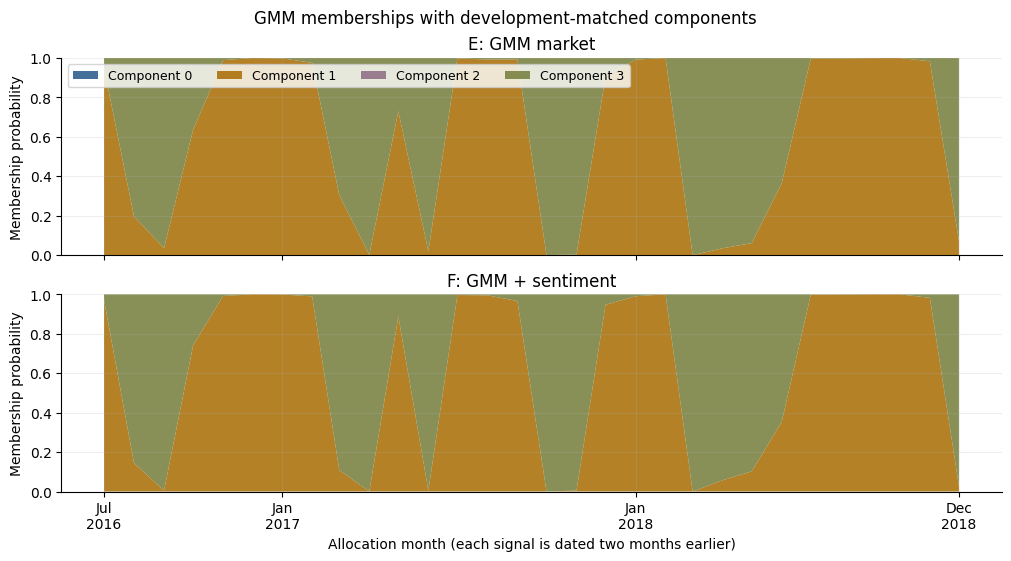

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, layout="constrained")
component_colors = ["#235789", "#A76B00", "#8C6A82", "#737D39"][:selected["GMM"]]
for ax, key, p in [(axes[0], "E", probabilities["E"]), (axes[1], "F", matched_gmm)]:
    ax.stackplot(test_dates, p.loc[signal_dates].to_numpy().T,
                 labels=[f"Component {j}" for j in p.columns], colors=component_colors, alpha=.85)
    ax.set(title=f"{key}: {DESCRIPTIONS[key]}", ylabel="Membership probability", ylim=(0, 1))
axes[0].legend(loc="upper left", ncol=selected["GMM"], fontsize=9)
axes[1].set_xticks([test_dates[0], pd.Timestamp("2017-01-01"), pd.Timestamp("2018-01-01"), test_dates[-1]])
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[1].set_xlabel("Allocation month (each signal is dated two months earlier)")
fig.suptitle("GMM memberships with development-matched components")
plt.show()

## 5. Portfolio construction and backtesting
### 5.1 Conditional moments and common optimizer
For component $j$, historical observations have weights $a_{u,j}=p_{u-2,j}$. Compute weighted population moments as in Notebooks 02–03, with effective size $n_j=(\sum_u a_{u,j})^2/\sum_u a_{u,j}^2$. If $n_j<12$, use unconditional moments; otherwise blend conditional and unconditional distributions with $\alpha_j=n_j/(n_j+24)$. Both this blend and the current-probability mixture include between-mean dispersion through second moments:
$$\mu=\sum_j p_{c,j}\mu_j,\qquad
\Sigma=\sum_j p_{c,j}(\Sigma_j+\mu_j\mu_j^\top)-\mu\mu^\top.$$
Then $\widehat\mu=0.5\mu$ and $\widehat\Sigma=0.8\Sigma+0.2\operatorname{diag}(\Sigma)+10^{-8}I$.

The unchanged SLSQP optimizer solves
$$\max_w\left(w^\top\widehat\mu-\frac{5}{2}w^\top\widehat\Sigma w\right),\qquad
\mathbf1^\top w=1,\quad 0\le w_i\le0.60.$$
Strategy A fixes $w_i=1/5$; B–F share this optimizer. All six share the same assets, evaluation dates, accounting engine and cost rule. The five core functions below are copied from Notebook 03; additional checks and diagnostics wrap their unchanged calculations.

In [8]:
def raw_moments(values, weights=None):
    a=np.asarray(values,dtype=float)
    p=np.ones(len(a)) if weights is None else np.asarray(weights,dtype=float)
    p=p/p.sum()
    mu=p@a; centered=a-mu
    cov=(centered*p[:,None]).T@centered
    return mu,cov

def regularize(mu,cov):
    cov=(1-COV_SHRINK)*cov+COV_SHRINK*np.diag(np.diag(cov))
    cov=(cov+cov.T)/2+np.eye(len(mu))*1e-8
    return (1-MEAN_SHRINK)*mu,cov

def optimize(mu,cov,gamma=GAMMA):
    n=len(mu)
    objective=lambda w: gamma/2*(w@cov@w)-w@mu
    gradient=lambda w: gamma*(cov@w)-mu
    result=minimize(objective,np.repeat(1/n,n),jac=gradient,method='SLSQP',
        bounds=[(0,CAP)]*n,constraints={'type':'eq','fun':lambda w:w.sum()-1,
        'jac':lambda w:np.ones(n)},options={'ftol':1e-12,'maxiter':500})
    if not result.success: raise RuntimeError(result.message)
    w=result.x
    assert abs(w.sum()-1)<1e-8 and w.min()>-1e-8 and w.max()<CAP+1e-8
    return w

def blend_moments(mu_a,cov_a,mu_b,cov_b,alpha):
    mu=alpha*mu_a+(1-alpha)*mu_b
    second=alpha*(cov_a+np.outer(mu_a,mu_a))+(1-alpha)*(cov_b+np.outer(mu_b,mu_b))
    return mu,second-np.outer(mu,mu)

In [9]:
def conditional_moments(history,probabilities,cutoff):
    # Outcome u is paired with signal u-2; align by actual calendar month.
    signals=history.index-pd.DateOffset(months=LAG)
    ok=signals.isin(probabilities.index)
    outcomes=history.loc[ok]
    signals=signals[ok]
    prior_mu,prior_cov=raw_moments(history)
    historical_p=probabilities.loc[signals].to_numpy()
    current_p=probabilities.loc[cutoff].to_numpy()
    component_mu=[]; component_cov=[]; effective=[]; fallback=0
    for j in range(historical_p.shape[1]):
        a=historical_p[:,j]; mass=a.sum()
        neff=mass*mass/(a@a) if a@a>0 else 0.0
        effective.append(neff)
        if neff<MIN_EFFECTIVE:
            mu,cov=prior_mu,prior_cov; fallback+=1
        else:
            cm,cc=raw_moments(outcomes,a)
            mu,cov=blend_moments(cm,cc,prior_mu,prior_cov,neff/(neff+PRIOR))
        component_mu.append(mu);component_cov.append(cov)
    means=np.array(component_mu)
    mu=current_p@means
    second=sum(p*(c+np.outer(m,m)) for p,m,c in zip(current_p,means,component_cov))
    cov=second-np.outer(mu,mu)
    return mu,cov,{'effective_current':float(current_p@np.array(effective)),
                  'fallback_components':fallback,'latest_outcome':history.index.max()}

In [10]:
def validate_moments(mu, covariance):
    assert np.isfinite(mu).all() and np.isfinite(covariance).all()
    np.testing.assert_allclose(covariance, covariance.T, rtol=0, atol=1e-12)
    assert np.linalg.eigvalsh(covariance).min() >= -1e-12

def allocate(return_data, probability_tables, dates):
    weight_rows = {key: [] for key in NAMES}
    component_rows = []
    for date in dates:
        cutoff = date - pd.DateOffset(months=LAG)
        history = return_data.loc[:cutoff].tail(LOOKBACK)
        assert len(history) == LOOKBACK and history.index.max() == cutoff and cutoff > MODEL_END
        weight_rows["A"].append(np.repeat(1 / return_data.shape[1], return_data.shape[1]))
        mu, cov = regularize(*raw_moments(history))
        validate_moments(mu, cov)
        weight_rows["B"].append(optimize(mu, cov))
        signals = history.index - pd.DateOffset(months=LAG)
        for key, prob in probability_tables.items():
            assert signals.isin(prob.index).all()  # No shortened conditional window.
            mu, cov, info = conditional_moments(history, prob, cutoff)
            assert info["latest_outcome"] == cutoff
            validate_moments(mu, cov)
            mu, cov = regularize(mu, cov)
            validate_moments(mu, cov)
            weight_rows[key].append(optimize(mu, cov))
            for j in prob.columns:
                a = prob.loc[signals, j].to_numpy()
                n_eff = float(a.sum()**2 / (a @ a)) if (a @ a) > 0 else 0.0
                component_rows.append({"date": date, "strategy": key, "component": j,
                    "ESS": n_eff, "mass": a.sum(), "current_probability": prob.loc[cutoff, j],
                    "fallback": n_eff < MIN_EFFECTIVE,
                    "blend": n_eff/(n_eff+PRIOR) if n_eff >= MIN_EFFECTIVE else 0.0})
    weights = {key: pd.DataFrame(rows, index=dates, columns=return_data.columns)
               for key, rows in weight_rows.items()}
    for table in weights.values():
        assert table.index.equals(dates) and np.isfinite(table).all().all()
        np.testing.assert_allclose(table.sum(axis=1), 1, atol=1e-8)
        assert table.min().min() >= -1e-8 and table.max().max() <= CAP + 1e-8
    return weights, pd.DataFrame(component_rows)

weights, effective_audit = allocate(ret, probabilities, test_dates)
effective_summary = effective_audit.groupby(["strategy", "component"]).agg(
    min_ESS=("ESS", "min"), median_ESS=("ESS", "median"), max_ESS=("ESS", "max"),
    fallback_months=("fallback", "sum"), mean_current_probability=("current_probability", "mean"))
display(effective_summary.round(2))

min_ESS  median_ESS  max_ESS  fallback_months  \
strategy component                                                  
C        0            64.00       76.50    85.00                0   
         1            31.00       39.50    52.00                0   
         2             4.00        4.00     4.00               30   
D        0            37.00       45.50    56.00                0   
         1            60.00       70.50    79.00                0   
         2             4.00        4.00     4.00               30   
E        0             1.00        1.00    12.00               30   
         1            55.52       64.83    73.13                0   
         2            12.00       12.00    12.00                0   
         3            39.29       43.51    47.13                0   
F        0            12.00       12.00    12.00                0   
         1            55.07       64.01    72.42                0   
         2            40.01       44.39    47.88                0   
         3             1.00        1.00    12.00               30   

                    mean_current_probability  
strategy component                            
C        0                              0.87  
         1                              0.13  
         2                              0.00  
D        0                              0.20  
         1                              0.80  
         2                              0.00  
E        0                              0.00  
         1                              0.61  
         2                              0.00  
         3                              0.39  
F        0                              0.00  
         1                              0.61  
         2                              0.39  
         3                              0.00

Rounded ESS values in the preceding table may appear equal to the threshold; the fallback test uses full precision. The rare KMeans component falls back in all 30 windows.

### 5.2 Turnover, costs and wealth
Copy Notebook 03's accounting: pretrade weights drift with the previous month's realized price changes. Turnover is the **sum** of absolute traded weights, with no division by two; initial turnover from cash is one. At fee $f=10/10{,}000$,
$$TO_t=\sum_i|w_{i,t}-\widetilde w_{i,t}|,\quad
R_t^{\mathrm{net}}=(1-fTO_t)(1+w_t^\top r_t)-1,\quad
\widetilde w_{i,t+1}=\frac{w_{i,t}(1+r_{i,t})}{1+w_t^\top r_t}.$$
This preserves the project's stylized fee convention, including its drift treatment. The monthly-average price proxies do not establish that these trades or pretrade valuations were historically executable. Costs are evaluated after weight selection and do not change the optimization objective.

In [11]:
def backtest(weight_table,fee_bps):
    pretrade=np.zeros(ret.shape[1]); rows=[]
    for date,wrow in weight_table.iterrows():
        w=wrow.to_numpy(); r=ret.loc[date].to_numpy()
        turnover=np.abs(w-pretrade).sum()
        gross=float(w@r);cost=fee_bps/10000*turnover
        net=(1-cost)*(1+gross)-1
        rows.append([gross,net,turnover,cost])
        pretrade=w*(1+r)/(1+gross)
    return pd.DataFrame(rows,index=weight_table.index,
                        columns=['gross_return','net_return','turnover','cost_fraction'])

In [12]:
paths = {key: backtest(w, FEE_BPS) for key, w in weights.items()}
net = pd.DataFrame({key: paths[key].net_return for key in NAMES})
gross = pd.DataFrame({key: paths[key].gross_return for key in NAMES})
wealth = (1 + net).cumprod()
initial_date = test_dates[0] - pd.DateOffset(months=1)
wealth_with_start = pd.concat([pd.DataFrame(1., index=[initial_date], columns=NAMES), wealth])
drawdown = wealth_with_start / wealth_with_start.cummax() - 1

# Independent vectorized reconstruction checks every monthly cash-flow calculation.
for key, w in weights.items():
    r = ret.loc[test_dates, w.columns]
    independently_gross = (w * r).sum(axis=1)
    drifted = w.mul(1+r).div(1+independently_gross, axis=0).shift(1).fillna(0)
    independently_turnover = (w-drifted).abs().sum(axis=1)
    independently_net = (1-FEE_BPS/10000*independently_turnover)*(1+independently_gross)-1
    np.testing.assert_allclose(paths[key].gross_return, independently_gross, atol=1e-12)
    np.testing.assert_allclose(paths[key].turnover, independently_turnover, atol=1e-12)
    np.testing.assert_allclose(net[key], independently_net, atol=1e-12)
    assert net[key].index.equals(test_dates) and np.isfinite(net[key]).all()
    assert np.isclose(paths[key].turnover.iloc[0], 1)
    assert (net[key] <= gross[key]+1e-12).all()
    np.testing.assert_allclose(backtest(w, 0).net_return, gross[key], atol=1e-12)
    assert (backtest(w, 25).net_return <= net[key]+1e-12).all()
print("PASS: common 30-month sample, valid moments, feasible weights, drift, initial investment and costs.")

PASS: common 30-month sample, valid moments, feasible weights, drift, initial investment and costs.


## 6. Empirical results and uncertainty
### 6.1 Net performance
For $T=30$ monthly net observations, $SR=\sqrt{12}\,\bar R/s_R$, with the same zero risk-free proxy as earlier notebooks; $\sigma_{\mathrm{ann}}=\sqrt{12}\,s_R$, $\mathrm{CAGR}=[\prod_t(1+R_t)]^{12/T}-1$. Maximum drawdown includes initial wealth one. Average monthly turnover includes the initial cash investment. All metrics describe price-proxy portfolios net of 10 bp per unit of turnover.

In [13]:
def metrics(returns,turnover):
    vol=returns.std(ddof=1)*np.sqrt(12)
    curve=pd.concat([pd.Series([1.]),(1+returns).cumprod().reset_index(drop=True)],ignore_index=True)
    dd=curve/curve.cummax()-1
    return pd.Series({'CAGR':(1+returns).prod()**(12/len(returns))-1,
        'annualized_vol':vol,'Sharpe_rf0':returns.mean()*12/vol if vol>0 else np.nan,
        'max_drawdown':dd.min(),'mean_monthly_turnover':turnover.mean(),
        'positive_month_fraction':returns.gt(0).mean(),'total_return':(1+returns).prod()-1})

summary = pd.DataFrame({key: metrics(net[key], paths[key].turnover) for key in NAMES}).T
summary["terminal_wealth"] = wealth.iloc[-1]
performance = summary[["Sharpe_rf0", "CAGR", "annualized_vol", "max_drawdown",
                       "mean_monthly_turnover", "terminal_wealth"]].copy()
performance.index = [f"{key}: {DESCRIPTIONS[key]}" for key in NAMES]
performance.columns = ["Sharpe (rf=0)", "CAGR", "Annual volatility", "Max drawdown", "Monthly turnover", "Final wealth"]
display(performance.style.format({"Sharpe (rf=0)": "{:.3f}", "CAGR": "{:.2%}",
    "Annual volatility": "{:.2%}", "Max drawdown": "{:.2%}", "Monthly turnover": "{:.2%}", "Final wealth": "{:.3f}"}))
# Independent metric checks using NumPy and compounded wealth.
np.testing.assert_allclose(summary.Sharpe_rf0, np.sqrt(12)*net.to_numpy().mean(axis=0)/net.to_numpy().std(axis=0, ddof=1))
np.testing.assert_allclose(summary.CAGR, wealth.iloc[-1].to_numpy()**(12/len(test_dates))-1)
np.testing.assert_allclose(summary.max_drawdown, drawdown.min())

,Sharpe (rf=0),CAGR,Annual volatility,Max drawdown,Monthly turnover,Final wealth
A: Equal weight,0.643,8.20%,13.68%,-10.24%,7.30%,1.218
B: Markowitz,0.346,2.82%,9.19%,-11.35%,8.94%,1.072
C: KMeans market,0.681,5.78%,8.81%,-11.16%,18.31%,1.151
D: KMeans + sentiment,0.513,4.39%,9.19%,-11.32%,26.44%,1.114
E: GMM market,0.439,4.42%,11.26%,-9.72%,26.27%,1.114
F: GMM + sentiment,0.410,4.10%,11.30%,-9.69%,27.22%,1.106


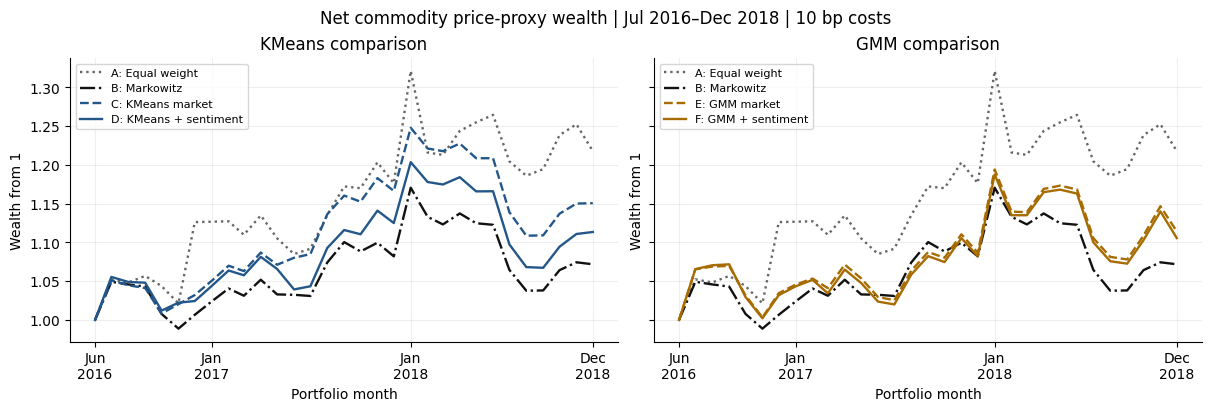

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True, layout="constrained")
for ax, keys, title in [(axes[0], "ABCD", "KMeans comparison"), (axes[1], "ABEF", "GMM comparison")]:
    for key in keys:
        ax.plot(wealth_with_start.index, wealth_with_start[key], color=COLORS[key], linestyle=STYLES[key],
                linewidth=1.7, label=f"{key}: {DESCRIPTIONS[key]}")
    ax.set(title=title, xlabel="Portfolio month", ylabel="Wealth from 1")
    ax.set_xticks([initial_date, pd.Timestamp("2017-01-01"), pd.Timestamp("2018-01-01"), test_dates[-1]])
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.legend(fontsize=8, loc="best")
fig.suptitle("Net commodity price-proxy wealth | Jul 2016–Dec 2018 | 10 bp costs")
plt.show()

### 6.2 Primary paired comparisons
Reuse the circular block bootstrap from Notebooks 02–03: 1,000 replications, six-month blocks, seed 42. The same resampled month indices apply to all six strategies, preserving pairing and some serial dependence. The two contrasts are always **D minus C** and **F minus E**. Percentile 95% intervals are approximate; they condition on fitted models and observed portfolios, without refitting or correcting for prior research selection. With only five six-month blocks per resample, inference is fragile. Intervals containing zero do not establish a positive effect.

,Sharpe difference,95% lower,95% upper
KMeans: D − C,-0.1681,-0.6333,0.0619
GMM: F − E,-0.0284,-0.0807,0.0097


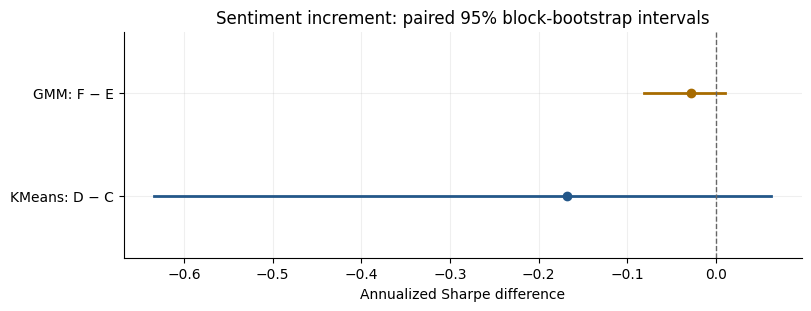

In [15]:
PAIRS = {"KMeans: D − C": ("D", "C"), "GMM: F − E": ("F", "E")}
def paired_bootstrap(returns, block=6, replications=1000):
    rng = np.random.default_rng(SEED)
    n = len(returns)
    boot = []
    for _ in range(replications):
        starts = rng.integers(0, n, size=int(np.ceil(n/block)))
        indices = np.concatenate([(start + np.arange(block)) % n for start in starts])[:n]
        sample = returns.iloc[indices]
        sr = sample.mean()/sample.std(ddof=1)*np.sqrt(12)
        boot.append([sr[a]-sr[b] for a, b in PAIRS.values()])
    samples = np.asarray(boot)
    assert np.isfinite(samples).all()
    observed_sr = returns.mean()/returns.std(ddof=1)*np.sqrt(12)
    result = pd.DataFrame({"Sharpe difference": [observed_sr[a]-observed_sr[b] for a, b in PAIRS.values()],
        "95% lower": np.quantile(samples, .025, axis=0),
        "95% upper": np.quantile(samples, .975, axis=0)}, index=PAIRS)
    return result, samples

primary, bootstrap_samples = paired_bootstrap(net)
for pair, (a, b) in PAIRS.items():
    assert np.isclose(primary.loc[pair, "Sharpe difference"], summary.loc[a, "Sharpe_rf0"]-summary.loc[b, "Sharpe_rf0"])
display(primary.round(4))
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
for i, (name, row) in enumerate(primary.iterrows()):
    ax.plot([row["95% lower"], row["95% upper"]], [i, i], color=["#235789", "#A76B00"][i], linewidth=2)
    ax.scatter(row["Sharpe difference"], i, color=["#235789", "#A76B00"][i], marker="o", zorder=3)
ax.axvline(0, color=".4", linewidth=1, linestyle="--")
ax.set_yticks(range(2), primary.index)
ax.set(xlabel="Annualized Sharpe difference", ylim=(-.6, 1.6),
       title="Sentiment increment: paired 95% block-bootstrap intervals")
plt.show()

### 6.3 Changes in allocations and turnover
A regime change need not improve forecasts or materially change the optimized portfolio. Compare mean asset-weight differences and the monthly half-$L^1$ distance $\frac12\sum_i|w^{M+S}_{i,t}-w^M_{i,t}|$ between paired target portfolios. This distance measures allocation disagreement; it is distinct from the full-$L^1$ turnover used for fees.

,Mean target distance,Turnover change,Δ weight: brent,Δ weight: natural_gas_us,Δ weight: gold,Δ weight: silver,Δ weight: copper
comparison,,,,,,,
KMeans: D − C,+3.42%,+8.13%,+1.57%,-0.06%,-0.47%,+0.38%,-1.42%
GMM: F − E,+1.29%,+0.96%,+0.40%,-0.09%,+0.00%,-0.21%,-0.10%


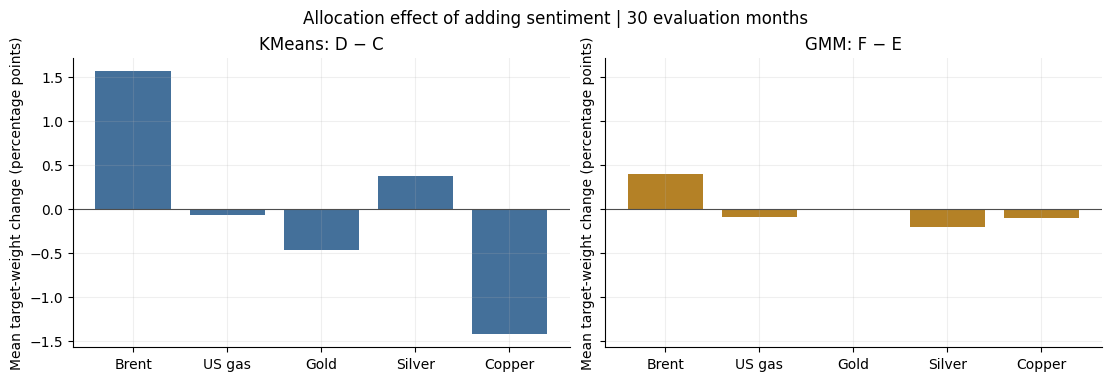

In [16]:
allocation_rows = []
for pair, (a, b) in PAIRS.items():
    allocation_rows.append({"comparison": pair,
        "Mean target distance": (weights[a]-weights[b]).abs().sum(axis=1).mean()/2,
        "Turnover change": paths[a].turnover.mean()-paths[b].turnover.mean(),
        **{f"Δ weight: {asset}": weights[a][asset].mean()-weights[b][asset].mean() for asset in ret.columns}})
allocation_changes = pd.DataFrame(allocation_rows).set_index("comparison")
display(allocation_changes.style.format("{:+.2%}"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True, layout="constrained")
asset_labels = ["Brent", "US gas", "Gold", "Silver", "Copper"]
for ax, (pair, (a, b)) in zip(axes, PAIRS.items()):
    changes = 100*(weights[a].mean()-weights[b].mean())
    ax.bar(asset_labels, changes, color=COLORS[a], alpha=.85)
    ax.axhline(0, color=".3", linewidth=.8)
    ax.set(title=pair, ylabel="Mean target-weight change (percentage points)")
fig.suptitle("Allocation effect of adding sentiment | 30 evaluation months")
plt.show()

In [17]:
for name, row in primary.iterrows():
    a, b = PAIRS[name]
    interval = f"[{row['95% lower']:.3f}, {row['95% upper']:.3f}]"
    interpretation = ("The interval includes zero; a positive effect is not established."
                      if row["95% lower"] <= 0 <= row["95% upper"] else
                      "The interval excludes zero, but remains conditional on this short, previously examined sample.")
    display(Markdown(f"**{name}:** Sharpe changes from {summary.loc[b, 'Sharpe_rf0']:.3f} to "
        f"{summary.loc[a, 'Sharpe_rf0']:.3f} (Δ {row['Sharpe difference']:+.3f}; approximate 95% interval {interval}). "
        f"Mean allocation distance is {allocation_changes.loc[name, 'Mean target distance']:.2%}; "
        f"monthly turnover changes by {100*allocation_changes.loc[name, 'Turnover change']:+.2f} percentage points. "
        + interpretation))
eval_regimes = regime_changes.loc["Evaluation signals"]
display(Markdown(f"**Regime change:** evaluation-signal ARI is {eval_regimes['KMeans ARI (C,D)']:.3f} "
    f"for KMeans and {eval_regimes['GMM hard ARI (E,F)']:.3f} for hard GMM assignments. "
    f"Matched GMM membership vectors differ by mean total variation {eval_regimes['GMM mean probability TV']:.3f}. "
    "These diagnostics describe changed partitions and membership, not improved predictive accuracy."))

**KMeans: D − C:** Sharpe changes from 0.681 to 0.513 (Δ -0.168; approximate 95% interval [-0.633, 0.062]). Mean allocation distance is 3.42%; monthly turnover changes by +8.13 percentage points. The interval includes zero; a positive effect is not established.

**GMM: F − E:** Sharpe changes from 0.439 to 0.410 (Δ -0.028; approximate 95% interval [-0.081, 0.010]). Mean allocation distance is 1.29%; monthly turnover changes by +0.96 percentage points. The interval includes zero; a positive effect is not established.

**Regime change:** evaluation-signal ARI is 0.687 for KMeans and 1.000 for hard GMM assignments. Matched GMM membership vectors differ by mean total variation 0.027. These diagnostics describe changed partitions and membership, not improved predictive accuracy.

## 7. Robustness checks and limitations
### 7.1 Future-data perturbation and estimator checks
For every evaluation date, replace all returns and all membership vectors **after its information cutoff** with different values; earlier target allocations must remain identical. Separately perturb raw monthly prices, monthly FRED observations and dated news after May 2017, rebuild features, repeat market-only selection and development fitting, and replay all decisions through July 2017. This checks causal feature construction and frozen fitting as well as allocation slicing. These algorithmic checks cannot verify historical publication or annotation availability.

In [18]:
# Every evaluation cutoff: forbidden future values cannot affect the current target.
rng = np.random.default_rng(2026)
max_weight_error = 0.0
for date in test_dates:
    cutoff = date - pd.DateOffset(months=LAG)
    changed_returns = ret.copy()
    future = changed_returns.index > cutoff
    changed_returns.loc[future] = rng.uniform(-.4, .5, size=(future.sum(), ret.shape[1]))
    changed_p = {}
    for key, p in probabilities.items():
        changed_p[key] = p.copy()
        mask = p.index > cutoff
        changed_p[key].loc[mask] = rng.dirichlet(np.ones(p.shape[1]), size=mask.sum())
    replay, _ = allocate(changed_returns, changed_p, pd.DatetimeIndex([date]))
    for key in NAMES:
        error = np.max(np.abs(replay[key].loc[date]-weights[key].loc[date]))
        max_weight_error = max(max_weight_error, error)
        np.testing.assert_allclose(replay[key].loc[date], weights[key].loc[date], rtol=0, atol=1e-10)

# Rebuild from perturbed inputs, including the news cleaning/aggregation pipeline.
cutoff = pd.Timestamp("2017-05-01")
changed_prices, changed_fred, changed_raw_news = prices.astype(float).copy(), fred.copy(), raw_news.copy()
future = prices.index > cutoff
changed_prices.loc[future] *= np.exp(rng.normal(0, .4, (future.sum(), prices.shape[1])))
future_fred = fred.index > cutoff
changed_fred.loc[future_fred] *= 1.4
raw_dates = pd.to_datetime(changed_raw_news.Dates.astype("string").str.strip(), format="%d-%m-%Y", errors="coerce")
changed_raw_news.loc[raw_dates > cutoff + pd.offsets.MonthEnd(0), "Price Sentiment"] = "negative"
changed_clean, _ = clean_news(changed_raw_news)
changed_sentiment = aggregate_news(changed_clean)
changed_market = market_features(changed_prices, changed_fred).loc[common]
changed_sets = {"market": changed_market,
                "sentiment": changed_market.join(changed_sentiment[["gold_news_sentiment"]])}
for key, data in feature_sets.items():
    pd.testing.assert_frame_equal(changed_sets[key].loc[:cutoff], data.loc[:cutoff])
changed_counts, changed_selection = select_counts(changed_market)
assert changed_counts == selected
pd.testing.assert_frame_equal(changed_selection, selection)
changed_models, changed_probabilities = fit_regimes(changed_sets, changed_counts)
for key in probabilities:
    np.testing.assert_allclose(changed_models[key]["scaler"].mean_, model_store[key]["scaler"].mean_)
    np.testing.assert_allclose(changed_probabilities[key].loc[:cutoff], probabilities[key].loc[:cutoff], atol=1e-12)
replay_dates = test_dates[test_dates <= cutoff + pd.DateOffset(months=LAG)]
replay, _ = allocate(changed_prices.pct_change(fill_method=None).dropna(), changed_probabilities, replay_dates)
for key in NAMES:
    np.testing.assert_allclose(replay[key], weights[key].loc[replay_dates], rtol=0, atol=1e-10)

# Independent weighted-moment and total-covariance checks on an actual historical window.
history = ret.loc[:signal_dates[0]].tail(LOOKBACK)
a = probabilities["E"].loc[history.index-pd.DateOffset(months=LAG)].iloc[:, 0].to_numpy()
mu, cov = raw_moments(history, a)
np.testing.assert_allclose(mu, np.average(history, axis=0, weights=a))
np.testing.assert_allclose(cov, np.cov(history.to_numpy().T, aweights=a, ddof=0), atol=1e-12)
mu0, cov0 = raw_moments(history)
alpha = .37
mix_mu, mix_cov = blend_moments(mu, cov, mu0, cov0, alpha)
independent_cov = alpha*cov+(1-alpha)*cov0+alpha*(1-alpha)*np.outer(mu-mu0, mu-mu0)
np.testing.assert_allclose(mix_cov, independent_cov, atol=1e-12)
print(f"PASS: 30 cutoff perturbations (max target-weight error {max_weight_error:.2e}); "
      f"raw-input reconstruction, selection/refit and {len(replay_dates)}-month replay; weighted moments and covariance mixing.")

PASS: 30 cutoff perturbations (max target-weight error 2.22e-16); raw-input reconstruction, selection/refit and 13-month replay; weighted moments and covariance mixing.


### 7.2 Limited sensitivity analysis
Keep the main model and portfolio settings fixed. Reprice the same weights at 0, 10 and 25 bp, and inspect paired bootstrap intervals at block lengths 3, 6 and 12 months. The six-month interval remains primary. These diagnostics are not a search for favorable parameters. Numerical regime stability is assessed with seeds 0, 7, 21 and 99 on development data, holding selected counts fixed; no alternative strategy is selected by its evaluation return.

In [19]:
cost_rows = []
for fee in [0, 10, 25]:
    fee_net = pd.DataFrame({key: backtest(weights[key], fee).net_return for key in NAMES})
    sr = fee_net.mean()/fee_net.std(ddof=1)*np.sqrt(12)
    cost_rows.append({"Fee (bp)": fee, **{pair: sr[a]-sr[b] for pair, (a, b) in PAIRS.items()}})
display(pd.DataFrame(cost_rows).set_index("Fee (bp)").round(4))
block_rows = []
for block in [3, 6, 12]:
    estimates = primary if block == 6 else paired_bootstrap(net, block=block)[0]
    block_rows.append(estimates.assign(block_months=block).set_index("block_months", append=True))
block_sensitivity = pd.concat(block_rows)
display(block_sensitivity.round(4))

stability_rows = []
for key, entry in model_store.items():
    data = feature_sets[entry["features"]]
    z = entry["scaler"].transform(data.loc[dev_dates])
    for seed in [0, 7, 21, 99]:
        k = selected[entry["algorithm"]]
        alternative = (KMeans(n_clusters=k, n_init=50, random_state=seed) if entry["algorithm"] == "KMeans" else
            GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                            n_init=20, max_iter=500, random_state=seed))
        alternative.fit(z)
        assert alternative.n_iter_ < alternative.max_iter
        if entry["algorithm"] == "GMM":
            assert alternative.converged_
        stability_rows.append({"strategy": key, "seed": seed,
            "development ARI": adjusted_rand_score(labels.loc[dev_dates, key], alternative.predict(z))})
stability = pd.DataFrame(stability_rows).groupby("strategy")["development ARI"].agg(["min", "median", "max"])
display(stability.round(3))

,KMeans: D − C,GMM: F − E
Fee (bp),,
0,-0.1576,-0.0273
10,-0.1681,-0.0284
25,-0.1838,-0.0299


,,Sharpe difference,95% lower,95% upper
,block_months,,,
KMeans: D − C,3,-0.1681,-0.6847,0.0823
GMM: F − E,3,-0.0284,-0.0850,0.0115
KMeans: D − C,6,-0.1681,-0.6333,0.0619
GMM: F − E,6,-0.0284,-0.0807,0.0097
KMeans: D − C,12,-0.1681,-0.6218,0.0675
GMM: F − E,12,-0.0284,-0.0788,0.0123


,min,median,max
strategy,,,
C,0.934,1.000,1.000
D,0.871,0.902,1.000
E,0.631,0.810,0.810
F,0.469,0.648,0.811


**Observed sensitivity:** both Sharpe differences remain negative at 0, 10 and 25 bp, and all displayed block-length intervals include zero. Development seed ARI ranges from 0.934–1.000 (C), 0.871–1.000 (D), 0.631–0.810 (E), and 0.469–0.811 (F). GMM solutions are materially sensitive to initialization, despite convergence; the fixed seed is retained without searching for favorable evaluation performance.

### 7.3 Scientific limitations
- **Short, previously inspected evaluation:** 30 monthly observations provide little evidence about persistent allocation gains. Earlier project development examined these dates; chronological separation does not undo research selection.
- **Regime weakness and instability:** silhouette, component occupancy, effective sample sizes and seed agreement must be read together. A converged fit is not an economically stable regime model. Overlapping price windows mechanically induce persistence; rare components require unconditional fallback and strong blending.
- **Narrow sentiment coverage:** the feature concerns gold, whereas four of five assets are other commodities. One standardized sentiment dimension may add little beside 21 market dimensions. Many headlines summarize past prices; the supplied categorical labels and `none` denominator are retained rather than optimized for performance.
- **Retrospective news annotation:** headline dates do not establish contemporaneous collection, classification or full-month coverage. Invalid-date exclusions and changing news density may affect sentiment. No historical label-availability timestamps are supplied, so a two-month delay cannot establish point-in-time validity.
- **FRED vintages and availability:** this is a known retrospective-data limitation, not just a hypothetical revision risk. The Federal Reserve introduced the goods-and-services dollar-index methodology underlying DTWEXBGS on **4 February 2019**, with a historical series back to January 2006 ([Federal Reserve implementation notice](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html)). That definition was therefore unavailable throughout the 2016–2018 evaluation. We retain it to preserve Notebook 03's specification and make a paired retrospective comparison; a two-month lag does not repair this limitation. Other FRED and World Bank snapshots may also contain later revisions.
- **Price proxies and costs:** World Bank monthly-average benchmark-price changes omit futures roll yield, collateral returns and executable prices. They cannot be interpreted as realized futures or ETF total returns. Turnover and proportional fees are a common synthetic accounting convention, not measured trading costs.
- **Bootstrap limitations:** few blocks, serial dependence, unstable Sharpe ratios, no model refitting and no adjustment for prior selection limit interval coverage. Intervals containing zero are inconclusive, not proof of equivalence. The two contrasts and secondary sensitivities do not establish causality.

All required numerical sources were available for this execution. Historical publication vintages, news annotation timestamps and investable total-return data are **unavailable in the supplied inputs**; therefore those aspects remain unverified. Tests above address computational timing and consistency only.

**Verification record (11 November 2026).** All 20 code cells executed from a fresh kernel without errors. Independent checks reproduced all 9,397 cleaned records and 153 monthly aggregates from Notebook 04 and verified that the seven reused numerical functions are code-identical to Notebook 03. The saved figures, tables and equations were inspected in a rendered preview. Notebooks 01–04 and existing data/results were left unchanged.

## 8. Conclusion
The following conclusion is generated from the executed primary comparisons; neither algorithm is chosen as a winner using evaluation returns.

In [20]:
conclusion_parts = []
for name, row in primary.iterrows():
    a, b = PAIRS[name]
    direction = "increases" if row["Sharpe difference"] > 0 else "decreases"
    conclusion_parts.append(f"For **{name.split(':')[0]}**, adding sentiment {direction} sample Sharpe "
        f"by {abs(row['Sharpe difference']):.3f}, from {summary.loc[b, 'Sharpe_rf0']:.3f} to "
        f"{summary.loc[a, 'Sharpe_rf0']:.3f}; the approximate paired 95% interval is "
        f"[{row['95% lower']:.3f}, {row['95% upper']:.3f}].")
includes_zero = (primary["95% lower"].le(0) & primary["95% upper"].ge(0)).all()
conclusion_parts.append("Neither primary interval excludes zero, so this experiment does not establish an improvement "
    "in risk-adjusted allocation performance from gold-news sentiment." if includes_zero else
    "Read the signed effects and their intervals separately; an interval excluding zero remains exploratory evidence in this sample.")
conclusion_parts.append("The regime and allocation diagnostics quantify how sentiment changes the mechanism, while the "
    "paired performance comparisons test whether that change helps. The evidence is limited to 30 previously examined "
    "months and revised benchmark-price proxies. A stronger assessment requires new evaluation dates, contemporaneously "
    "available news labels and macro vintages, and investable commodity total returns under a fixed protocol.")
display(Markdown("\n\n".join(conclusion_parts)))

For **KMeans**, adding sentiment decreases sample Sharpe by 0.168, from 0.681 to 0.513; the approximate paired 95% interval is [-0.633, 0.062].

For **GMM**, adding sentiment decreases sample Sharpe by 0.028, from 0.439 to 0.410; the approximate paired 95% interval is [-0.081, 0.010].

Neither primary interval excludes zero, so this experiment does not establish an improvement in risk-adjusted allocation performance from gold-news sentiment.

The regime and allocation diagnostics quantify how sentiment changes the mechanism, while the paired performance comparisons test whether that change helps. The evidence is limited to 30 previously examined months and revised benchmark-price proxies. A stronger assessment requires new evaluation dates, contemporaneously available news labels and macro vintages, and investable commodity total returns under a fixed protocol.

**Implementation attribution.** This extension reuses the research design and executable methods of project Notebooks 01–04 and the cited course materials. Codex assisted with implementation, methodological checks and notebook presentation. Human co-author contributions should be reported by the authors; they are not inferred here.